In [115]:
%pip install numpy pandas scikit-learn imbalanced-learn joblib matplotlib seaborn xgboost

Note: you may need to restart the kernel to use updated packages.


In [116]:
import numpy as np
import pandas as pd
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import time


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score,precision_recall_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

In [117]:
print("Loading data...")

data_path = "creditcard.csv"  
data = pd.read_csv(data_path)

# Cleaning
data = data.drop_duplicates()
data = data.drop(['Time'], axis=1, errors='ignore')

print("Data Shape:", data.shape)
data.head()

Loading data...
Data Shape: (283726, 30)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


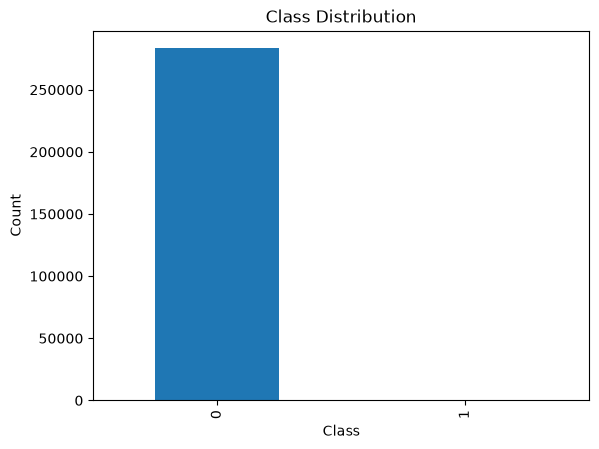

In [118]:
data["Class"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [119]:
X = data.drop('Class', axis=1)
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [120]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [121]:
print("Before SMOTE:")
print("Class distribution:", np.bincount(y_train))

print("\nApplying SMOTE...")
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print("\nAfter SMOTE:")
print("Class distribution:", np.bincount(y_train_res))

Before SMOTE:
Class distribution: [226602    378]

Applying SMOTE...

After SMOTE:
Class distribution: [226602 226602]


In [133]:
# from sklearn.metrics import precision_recall_curve
# import numpy as np

# precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# # F1 calculation
# f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

# # Best threshold
# best_idx = np.argmax(f1_scores)
# best_threshold = thresholds[best_idx]

# print("Best Threshold:", best_threshold)
# print("Best F1 Score:", f1_scores[best_idx])

best_threshold = .60

In [134]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='liblinear'
)

print("Training Logistic Regression...")
lr_model.fit(X_train_res, y_train_res)

# Probabilities
y_proba = lr_model.predict_proba(X_test)[:, 1]

threshold = best_threshold

y_pred = (y_proba > threshold).astype(int)

# Evaluation
print("\n=== Model Evaluation (Custom Threshold) ===")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

Training Logistic Regression...

=== Model Evaluation (Custom Threshold) ===
[[55538  1113]
 [   12    83]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.07      0.87      0.13        95

    accuracy                           0.98     56746
   macro avg       0.53      0.93      0.56     56746
weighted avg       1.00      0.98      0.99     56746

ROC-AUC Score: 0.9603772498093126


In [135]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
start = time.time()
rf_model.fit(X_train_res, y_train_res)
end = time.time()

print(f"Training Time: {end - start:.2f} seconds")

# Probabilities
y_proba = rf_model.predict_proba(X_test)[:, 1]

threshold = best_threshold
y_pred = (y_proba > threshold).astype(int)

# Evaluation
print("\n=== Model Evaluation ===")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

# Feature Importance
importances = rf_model.feature_importances_
feature_importance = pd.Series(importances, index=X.columns)

top_features = feature_importance.sort_values(ascending=False).head(5)

print("\n=== Top 5 Important Features ===")
print(top_features)

Training Random Forest...
Training Time: 126.84 seconds

=== Model Evaluation ===
[[56646     5]
 [   25    70]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC Score: 0.9724483889818453

=== Top 5 Important Features ===
V10    0.166345
V14    0.160336
V4     0.104640
V12    0.104488
V17    0.089619
dtype: float64


In [136]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
)
import pandas as pd
import time

# XGBoost Model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")
start = time.time()

xgb_model.fit(X_train_res, y_train_res)

end = time.time()

print(f"Training Time: {end - start:.2f} seconds")

# Predicted probabilities
y_proba = xgb_model.predict_proba(X_test)[:, 1]

# Threshold
threshold = best_threshold
y_pred = (y_proba > threshold).astype(int)

# Evaluation
print("\n=== Model Evaluation ===")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

# Feature Importance
importances = xgb_model.feature_importances_
feature_importance = pd.Series(importances, index=X.columns)

top_features = feature_importance.sort_values(ascending=False).head(5)

print("\n=== Top 5 Important Features ===")
print(top_features)

Training XGBoost...
Training Time: 7.00 seconds

=== Model Evaluation ===
[[56619    32]
 [   18    77]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.71      0.81      0.75        95

    accuracy                           1.00     56746
   macro avg       0.85      0.90      0.88     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC Score: 0.9701749121351506

=== Top 5 Important Features ===
V14    0.409706
V10    0.201697
V4     0.056939
V8     0.031133
V12    0.028245
dtype: float32


In [137]:
def evaluate_model(model, name, threshold=best_threshold):
    print(f"\n===== {name} =====")
    
    y_probs = model.predict_proba(X_test)[:, 1]
    y_pred = (y_probs > threshold).astype(int)
    
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    # Visualizing Confusion Matrix
    plt.figure(figsize=(3,2))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))


===== Logistic Regression =====

Confusion Matrix:
[[55538  1113]
 [   12    83]]


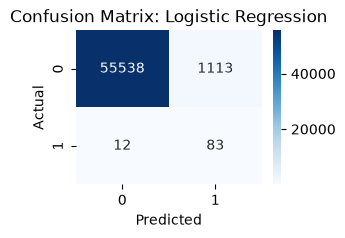


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.07      0.87      0.13        95

    accuracy                           0.98     56746
   macro avg       0.53      0.93      0.56     56746
weighted avg       1.00      0.98      0.99     56746


===== Random Forest =====

Confusion Matrix:
[[56646     5]
 [   25    70]]


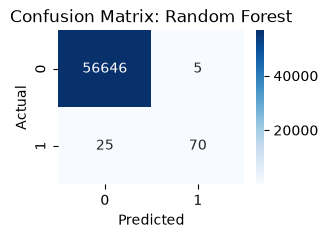


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746


===== XG Boost =====

Confusion Matrix:
[[56619    32]
 [   18    77]]


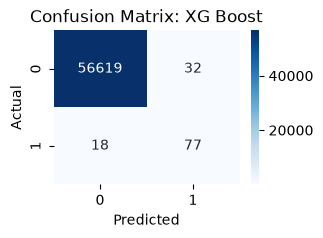


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.71      0.81      0.75        95

    accuracy                           1.00     56746
   macro avg       0.85      0.90      0.88     56746
weighted avg       1.00      1.00      1.00     56746



In [138]:
evaluate_model(lr_model, "Logistic Regression")
evaluate_model(rf_model, "Random Forest")
evaluate_model(xgb_model, "XG Boost")

In [139]:
joblib.dump(lr_model, 'logistic_model.pkl')
joblib.dump(rf_model, 'random_forest_model.pkl')
joblib.dump(xgb_model, 'XGB_model.pkl ')
joblib.dump(scaler, 'scaler.pkl')

print("All models saved successfully!")

All models saved successfully!


In [140]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XG Boost": xgb_model,
}

for name, model in models.items():
    y_probs = model.predict_proba(X_test)[:, 1]
    y_pred = (y_probs > best_threshold).astype(int)
    
    print(f"\n{name}")
    print("Fraud detected:", sum(y_pred))


Logistic Regression
Fraud detected: 1196

Random Forest
Fraud detected: 75

XG Boost
Fraud detected: 109


In [141]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XG Boost": xgb_model,
}

results = []

# Threshold (important for fraud detection)
threshold = best_threshold
for name, model in models.items():
    y_probs = model.predict_proba(X_test)[:, 1]
    y_pred = (y_probs > threshold).astype(int)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append([name, acc, prec, rec, f1])

# Convert to DataFrame
df_results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print(df_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.980175   0.069398  0.873684  0.128582
1        Random Forest  0.999471   0.933333  0.736842  0.823529
2             XG Boost  0.999119   0.706422  0.810526  0.754902


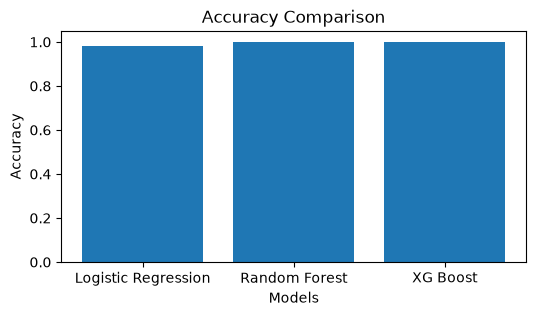

In [142]:
models = ['Logistic Regression', 'Random Forest', "XG Boost"]
accuracies = [
    df_results[df_results['Model'] == 'Logistic Regression']['Accuracy'].iloc[0],
    df_results[df_results['Model'] == 'Random Forest']['Accuracy'].iloc[0],
    df_results[df_results['Model'] == 'XG Boost']['Accuracy'].iloc[0]
]

plt.figure(figsize=(6,3))
plt.bar(models, accuracies)

plt.title("Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.show()

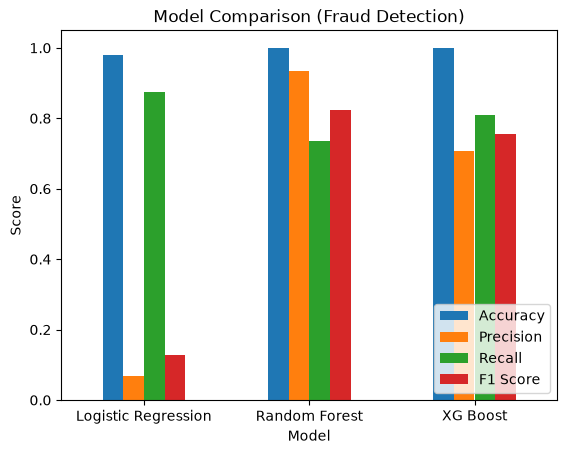

In [143]:
# Set index for better plotting
df_results.set_index("Model", inplace=True)

# Plot all metrics
df_results.plot(kind='bar')

plt.title("Model Comparison (Fraud Detection)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()
